In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from pyproj import Transformer
from sklearn.preprocessing import StandardScaler

divar_df = pd.read_csv('./Divar.csv')

mapping = {
    'بدون اتاق': 0,
    'یک': 1,
    'دو': 2,
    'سه': 3,
    'چهار': 4,
    'پنج یا بیشتر': 5,
}
divar_df['rooms_count'] = divar_df['rooms_count'].map(mapping)
divar_df['rooms_count'].fillna(divar_df['rooms_count'])
divar_df['rooms_count'] = pd.to_numeric(divar_df['rooms_count'], errors='coerce')


divar_df['building_size'] = pd.to_numeric(divar_df['building_size'], errors='coerce')
divar_df['location_latitude'] = pd.to_numeric(divar_df['location_latitude'], errors='coerce')
divar_df['location_longitude'] = pd.to_numeric(divar_df['location_longitude'], errors='coerce')


divar_df['final_price'] = pd.to_numeric(divar_df['price_value'], errors='coerce')


df_clean = divar_df[
    (divar_df['location_latitude'] > 25) & (divar_df['location_latitude'] < 40) &
    (divar_df['location_longitude'] > 44) & (divar_df['location_longitude'] < 64)
].copy()


df_clean = df_clean[df_clean['final_price'] > 10000000].copy()

q_low = df_clean['final_price'].quantile(0.01)
q_high = df_clean['final_price'].quantile(0.98)
df_clean = df_clean[(df_clean['final_price'] >= q_low) & (df_clean['final_price'] <= q_high)]


transformer = Transformer.from_crs("EPSG:4326", "EPSG:32639", always_xy=True)

df_clean['utm_x'], df_clean['utm_y'] = transformer.transform(
    df_clean['location_longitude'].values,
    df_clean['location_latitude'].values
)

features = ['utm_x', 'utm_y', 'final_price', 'building_size', 'rooms_count']
X = df_clean[features].dropna().copy()


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

/tmp/ipykernel_67173/3522368810.py:8: DtypeWarning: Columns (0: rent_to_single, 1: floor, 2: total_floors_count, 3: extra_person_capacity) have mixed types. Specify dtype option on import or set low_memory=False.
  divar_df = pd.read_csv('./Divar.csv')


## elbow method

In [44]:
WCSS = []

for k in range(1, 21):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    WCSS.append(kmeans.inertia_)

In [45]:
from kneed import KneeLocator

knee_loc = KneeLocator(range(1,21), WCSS, curve="convex", direction="decreasing")
best_k = knee_loc.elbow
print("best k:", best_k)

best k: 6


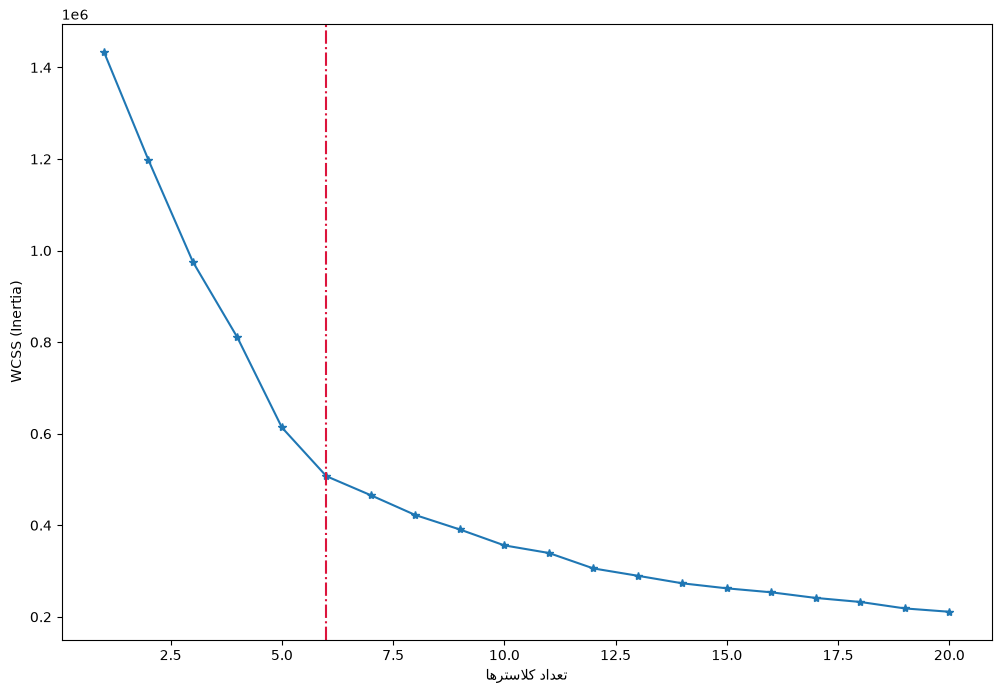

In [46]:
plt.figure(figsize=(12,8))
plt.plot(range(1,21), WCSS, marker='*')
plt.axvline(x=best_k, color='crimson', linestyle='-.')
plt.xlabel("تعداد کلاسترها")
plt.ylabel("WCSS (Inertia)")
plt.show()